In [1]:
!pwd

/Users/zagidull/Desktop/synosys/lina-s paper


In [2]:
import numpy as np
import pandas as pd
import os
import scipy.stats
import matplotlib.pyplot as plt

os.chdir('/Users/zagidull/Desktop/synosys/lina-s paper/')

In [3]:
df = pd.read_csv('data/SynoSys_27.02.2026-11.03.2026/bbi-(enhanced).csv')

In [4]:
df.head() 

,User Id,User First Name,User Last Name,User Email,Team Names,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Gap Duration (ms),Status,BBI Type
0,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,NaN,LOW_CONFIDENCE,Enhanced BBI
1,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,NaN,LOW_CONFIDENCE,Enhanced BBI
2,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,NaN,LOW_CONFIDENCE,Enhanced BBI
3,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,NaN,LOW_CONFIDENCE,Enhanced BBI
4,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,NaN,LOW_CONFIDENCE,Enhanced BBI


In [5]:
df['User Id'].nunique()

3

In [6]:
pd.DataFrame(map(lambda col: (col, df[col].nunique(), df[col].dtype ), df.columns))

# looks like these cols are not needed rn
# 'User First Name', 'User Last Name', 'User Email', 'Team Names', 'Group Names', 
# 'Calendar Date (Local)', 'Time Zone (Local)', 'Calendar Date (UTC)', 
# 'Gap Duration (ms)', 'BBI Type'

,0,1,2
0,User Id,3,object
1,User First Name,3,object
2,User Last Name,0,float64
3,User Email,3,object
4,Team Names,0,float64
5,Group Names,1,object
6,Calendar Date (Local),6,object
7,Start Time (Local),740949,object
8,Time Zone (Local),1,int64
9,Calendar Date (UTC),6,object


In [7]:
all(
    pd.to_datetime(df['Start Time (ms)'], unit='ms', utc=True) \
    + pd.to_timedelta(df['Time Zone (s)'], unit='s') \
    == pd.to_datetime(df['Start Time (Local)'], utc=True))

# looks like Start Time (ms) is in UTC, ie Start Time (ms)+ Time Zone (s)= Start Time (Local)

True

In [8]:
cols_drop=['User First Name', 'User Last Name', 'User Email', 'Team Names', 'Group Names', 'Calendar Date (Local)',
           'Start Time (Local)', 'Start Time (UTC)', 'Time Zone (Local)', 'Calendar Date (UTC)', 'Gap Duration (ms)', 'BBI Type']

In [9]:
df = df.drop(labels=cols_drop, axis='columns', inplace=False)

In [10]:
df.head()

,User Id,Start Time (ms),Time Zone (s),BBI (ms),Status
0,69aa9a01c272d7436ea5db59,1772789052000,3600,1007,LOW_CONFIDENCE
1,69aa9a01c272d7436ea5db59,1772789053508,3600,1507,LOW_CONFIDENCE
2,69aa9a01c272d7436ea5db59,1772789054131,3600,625,LOW_CONFIDENCE
3,69aa9a01c272d7436ea5db59,1772789054818,3600,687,LOW_CONFIDENCE
4,69aa9a01c272d7436ea5db59,1772789055474,3600,656,LOW_CONFIDENCE


In [11]:
# lets map user id to something simple, like 1-2-3

userid_map = dict(zip(set(df['User Id']), {1,2,3}))
df['User Id'] = df['User Id'].map(userid_map)


In [12]:
df.dtypes

User Id             int64
Start Time (ms)     int64
Time Zone (s)       int64
BBI (ms)            int64
Status             object
dtype: object

In [13]:
df.isna().sum()

User Id            0
Start Time (ms)    0
Time Zone (s)      0
BBI (ms)           0
Status             0
dtype: int64

In [14]:
df.Status.value_counts()

Status
LOW_CONFIDENCE     388613
HIGH_CONFIDENCE    352912
Name: count, dtype: int64

In [15]:
# lets stratify by Status and User, and see what's the difference in BBI between Low and High status
df.groupby(['User Id', 'Status'])['BBI (ms)'].agg(['min', 'max', 'mean', 'std']).round(0)

# looks like low confidence vals have higher means and std.

min    max   mean    std
User Id Status                                   
1       HIGH_CONFIDENCE  461   2570  966.0  200.0
        LOW_CONFIDENCE   453   2915  800.0  247.0
2       HIGH_CONFIDENCE  453   2069  903.0  200.0
        LOW_CONFIDENCE   453   6483  772.0  255.0
3       HIGH_CONFIDENCE  453   2281  952.0  150.0
        LOW_CONFIDENCE   208  16284  817.0  301.0

In [16]:
# now lets see if there is a relation with Time of Day
# lets assign a new col timeLocal_ms

df = df.assign(timeLocal_ms = df['Start Time (ms)']+df['Time Zone (s)']*1000)
df.head()

,User Id,Start Time (ms),Time Zone (s),BBI (ms),Status,timeLocal_ms
0,3,1772789052000,3600,1007,LOW_CONFIDENCE,1772792652000
1,3,1772789053508,3600,1507,LOW_CONFIDENCE,1772792653508
2,3,1772789054131,3600,625,LOW_CONFIDENCE,1772792654131
3,3,1772789054818,3600,687,LOW_CONFIDENCE,1772792654818
4,3,1772789055474,3600,656,LOW_CONFIDENCE,1772792655474


In [17]:
1_772_789_052_000+3_600*1000 == 1_772_792_652_000 # sanity check just for the first row

True

In [18]:
# lets drop 'Start Time (ms)' and 'Time Zone (s)' columns
df = df.drop(['Start Time (ms)', 'Time Zone (s)'], axis='columns', inplace=False)

In [19]:
# how long measurements were collected for, stratify by User Id

df.groupby('User Id')['timeLocal_ms'].agg(lambda x: pd.to_timedelta( max(x)-min(x), unit='ms' ))

User Id
1   2 days 03:48:42.720000
2   2 days 03:33:11.780000
3   5 days 02:48:04.204000
Name: timeLocal_ms, dtype: timedelta64[ns]

In [20]:
# let's see how much BBI values vary between users (level0), confidence levels (level1) and hours of the day (level2)
hour = pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour # level2 groupby column

gr = df.groupby(['User Id', 'Status', hour])['BBI (ms)']\
    .agg(['min', 'max', 'median', 'std', 'size'])

gr.groupby(level=[0,1]).mean().astype(int)\
    .rename(columns={'size':'num BBI measurements per hour', 'min':'min BBI', 'max':'max BBI', 'median':'median BBI', 'std':'std BBI'})

min BBI  max BBI  median BBI  std BBI  \
User Id Status                                                   
1       HIGH_CONFIDENCE      517     1695         932      119   
        LOW_CONFIDENCE       464     2347         792      259   
2       HIGH_CONFIDENCE      483     1720         855      140   
        LOW_CONFIDENCE       457     2765         724      255   
3       HIGH_CONFIDENCE      503     1734         897      107   
        LOW_CONFIDENCE       442    10379         797      332   

                         num BBI measurements per hour  
User Id Status                                          
1       HIGH_CONFIDENCE                           4033  
        LOW_CONFIDENCE                            3734  
2       HIGH_CONFIDENCE                           3913  
        LOW_CONFIDENCE                            5430  
3       HIGH_CONFIDENCE                           6757  
        LOW_CONFIDENCE                            7027

Text(0.5, 0, 'Hour')

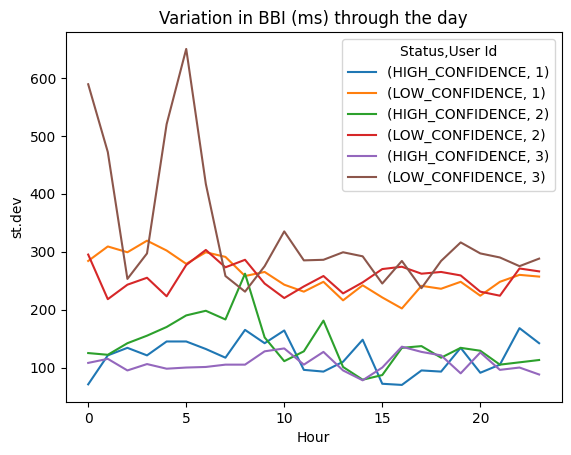

In [21]:
# plot hourly std stratified by user and confidence
ax = gr['std'].unstack(['Status', 'User Id']).round(0).plot()

ax.set_title('Variation in BBI (ms) through the day')
ax.set_ylabel('st.dev')
ax.set_xlabel('Hour')

In [22]:
# lets see how moments etc look like in groups, and also across entire data, and for reference normal dist of given mean/std

f = lambda v: [ np.mean(v).round(1), np.median(v).round(1), np.std(v).round(1), scipy.stats.skew(v).round(1), scipy.stats.kurtosis(v).round(1)]

# in stratified data
gr_robust = df.groupby(['User Id', 'Status', hour])['BBI (ms)']\
    .agg(['mean', 'median', 'std', 'skew', pd.Series.kurt ])\
    .groupby(level=[0,1]).mean().round(1)\
    .rename(columns={'mean':'mean BBI', 'median':'median BBI'})

# all data
gr_robust.loc[ ('all', 'all'), : ] = f( df['BBI (ms)'] )

# ref dist
ref_norm = scipy.stats.norm(loc=df['BBI (ms)'].mean(), scale=df['BBI (ms)'].std()) # loc is mean, scale is std
x = np.linspace(ref_norm.ppf(0.01), ref_norm.ppf(0.99), 1000)
gr_robust.loc[ ('ref', 'ref'), : ] = f( x )

gr_robust
#gr_robust.groupby(level=[0,1]).mean().round(1)\
#    .rename(columns={'mean':'mean BBI', 'median':'median BBI'}) # seems like in the low confidence group 

mean BBI  median BBI    std  skew   kurt
User Id Status                                                   
1       HIGH_CONFIDENCE     927.1       932.4  119.8   0.2    4.6
        LOW_CONFIDENCE      842.0       792.5  259.3   1.4    3.7
2       HIGH_CONFIDENCE     858.6       855.5  140.2   0.8    4.6
        LOW_CONFIDENCE      783.1       724.8  255.6   2.0    9.3
3       HIGH_CONFIDENCE     900.1       897.9  107.6   0.4    5.0
        LOW_CONFIDENCE      837.3       797.1  332.3   9.2  265.7
all     all                 866.9       841.0  245.8   5.0  206.3
ref     ref                 866.9       866.9  330.4   0.0   -1.2

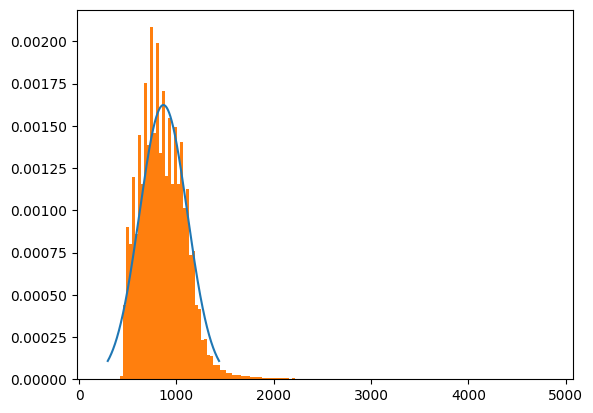

In [23]:
# compare all BBI with a normal 

fig, ax = plt.subplots(nrows=1, ncols=1)

ax.plot(x, ref_norm.pdf(x))
ax.hist(df.loc[df['BBI (ms)']<5_000, 'BBI (ms)'], bins=150, density=True)
plt.show()